### Hypothesentests: Ablehnungsbereich, ein- und zweiseitig, Fehler 1. und 2. Art - Übungen

In diesem Notebook geht es um **Hypothesentests**: Ist eine Münze gezinkt? Wirkt ein neues Medikament besser? Hat sich der Anteil der Kunden
verändert? Du formulierst eine **Nullhypothese**, bestimmst mit der Binomialverteilung einen **Ablehnungsbereich** und berechnest die
Wahrscheinlichkeiten für **Fehler 1. und 2. Art**.

sympy rechnet die Wahrscheinlichkeiten der Binomialverteilung exakt aus. Die Überlegungen (Welche Hypothese? Welche Seite? Welcher Fehler?)
bleiben bei dir.

Vorausgesetzt wird das Notebook *Wahrscheinlichkeit* (Binomialverteilung).

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy und `sympy.stats`, schaltet die Formel-Ausgabe ein
und lädt matplotlib. **Achtung:** `sympy.stats` verwendet `E` für den Erwartungswert und `P` für Wahrscheinlichkeiten. Verwende diese Namen nicht für eigene Variablen.

In [ ]:
from sympy import *
from sympy.stats import *
init_printing()
import matplotlib.pyplot as plt

## 1. Die kumulierte Binomialverteilung

#### P(X ≤ k) mit `cdf()`

Für eine binomialverteilte Zufallsgröße X berechnet `P(X <= k)` eine einzelne **kumulierte Wahrscheinlichkeit**.
Braucht man viele davon, ist `F = cdf(X)` schneller: Das ist ein Dictionary mit F[k] = P(X ≤ k) für alle k von 0 bis n.

Daraus folgen alle anderen Wahrscheinlichkeiten:

| gesucht | Formel |
|---|---|
| P(X ≥ k) | 1 − P(X ≤ k − 1) = `1 - F[k - 1]` |
| P(X < k) | P(X ≤ k − 1) = `F[k - 1]` |
| P(a ≤ X ≤ b) | `F[b] - F[a - 1]` |

In [ ]:
X = Binomial('X', 100, Rational(1, 2))
F = cdf(X)
display(N(F[40], 4), N(P(X <= 40), 4))
display(N(1 - F[59], 4))
N(F[55] - F[44], 4)

#### Aufgabe 1.1

X ist binomialverteilt mit n = 50 und p = 0,3. Berechne P(X ≤ 10) und P(X ≤ 20) mit 4 Ziffern (über `F`).

**Erwartete Ausgabe:**

$\displaystyle 0.07885$

$\displaystyle 0.9522$

In [ ]:
X = Binomial('X', 50, Rational(3, 10))
F = cdf(X)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 50, Rational(3, 10))
F = cdf(X)
display(N(F[10], 4))
N(F[20], 4)
```

</details>

#### Aufgabe 1.2

Berechne für dieselbe Verteilung P(X ≥ 20) und P(X > 20) mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 0.0848$

$\displaystyle 0.04776$

In [ ]:
X = Binomial('X', 50, Rational(3, 10))
F = cdf(X)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 50, Rational(3, 10))
F = cdf(X)
display(N(1 - F[19], 4))
N(1 - F[20], 4)
```

</details>

#### Aufgabe 1.3

Berechne P(10 ≤ X ≤ 20) und P(10 < X < 20) mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 0.912$

$\displaystyle 0.8363$

In [ ]:
X = Binomial('X', 50, Rational(3, 10))
F = cdf(X)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 50, Rational(3, 10))
F = cdf(X)
display(N(F[20] - F[9], 4))
N(F[19] - F[10], 4)
```

</details>

#### Aufgabe 1.4

Gib Erwartungswert und Standardabweichung (4 Ziffern) aus und die Wahrscheinlichkeit, dass X höchstens eine Standardabweichung vom Erwartungswert abweicht.

**Erwartete Ausgabe:**

$\displaystyle 15$

$\displaystyle 3.24$

$\displaystyle 0.7204$

In [ ]:
X = Binomial('X', 50, Rational(3, 10))
F = cdf(X)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 50, Rational(3, 10))
F = cdf(X)
mu, sigma = E(X), std(X)
display(mu, N(sigma, 4))
N(P((X >= mu - sigma) & (X <= mu + sigma)), 4)
```

</details>

#### Aufgabe 1.5

Bestimme das kleinste k mit P(X ≤ k) ≥ 0,9 für die Verteilung aus den vorigen Aufgaben (Schleife über F).

**Erwartete Ausgabe:**

$\displaystyle 19$

In [ ]:
X = Binomial('X', 50, Rational(3, 10))
F = cdf(X)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 50, Rational(3, 10))
F = cdf(X)
k = 0
while F[k] < Rational(9, 10):
    k += 1
k
```

</details>

#### Aufgabe 1.6

Bestimme das größte k mit P(X ≤ k) ≤ 0,05 (Schleife: erhöhe k, solange F[k + 1] ≤ 0,05 ist; beginne bei k = 0, da F[0] klein ist).

**Erwartete Ausgabe:**

$\displaystyle 9$

$\displaystyle \left( 0.04023, \  0.07885\right)$

In [ ]:
X = Binomial('X', 50, Rational(3, 10))
F = cdf(X)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 50, Rational(3, 10))
F = cdf(X)
k = 0
while F[k + 1] <= Rational(5, 100):
    k += 1
display(k)
(N(F[k], 4), N(F[k + 1], 4))
```

</details>

#### Aufgabe 1.7

Zeichne die kumulierte Verteilungsfunktion F als Treppen-Diagramm: `plt.step(werte, [N(F[k]) for k in werte], where='post')` mit werte = 0, ..., 50.

**Erwartete Ausgabe:**



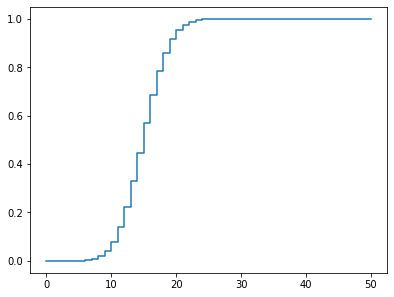

In [ ]:
X = Binomial('X', 50, Rational(3, 10))
F = cdf(X)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 50, Rational(3, 10))
F = cdf(X)
werte = list(range(51))
plt.step(werte, [N(F[k]) for k in werte], where='post')
plt.show()
```

</details>

#### Aufgabe 1.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
X = Binomial('X', 3, Rational(1, 2))
F = cdf(X)
display(F)
display(F[3])
1 - F[0]
```

In [ ]:
X = Binomial('X', 3, Rational(1, 2))
F = cdf(X)
display(F)
display(F[3])
1 - F[0]

## 2. Hypothesen, Entscheidungsregel und Fehler

#### Die Begriffe

Beispiel: Eine Münze soll auf Fairness geprüft werden. Man vermutet, dass sie zu oft Kopf zeigt.
- **Nullhypothese** H₀: p ≤ 0,5 (die Münze ist nicht zugunsten von Kopf gezinkt). **Gegenhypothese** H₁: p > 0,5.
- **Stichprobe:** n = 100 Würfe, X = Anzahl Kopf. Gerechnet wird mit dem Grenzfall p = 0,5 von H₀.
- **Entscheidungsregel:** Ist X im **Ablehnungsbereich** A = {k, ..., 100}, wird H₀ verworfen.
- **Fehler 1. Art:** H₀ ist wahr, wird aber verworfen. Seine Wahrscheinlichkeit ist α = P(X ∈ A) und soll höchstens das
  **Signifikanzniveau** (z. B. 5 %) sein.
- **Fehler 2. Art:** H₀ ist falsch, wird aber nicht verworfen. Seine Wahrscheinlichkeit β hängt vom wahren p ab.

Hier zuerst eine vorgegebene Entscheidungsregel: H₀ wird verworfen, wenn X ≥ 60.

In [ ]:
X = Binomial('X', 100, Rational(1, 2))
F = cdf(X)
alpha = 1 - F[59]
display(N(alpha, 4))
Y = Binomial('Y', 100, Rational(65, 100))
beta = cdf(Y)[59]
N(beta, 4)

#### Aufgabe 2.1

Eine Münze wird 50-mal geworfen. H₀: p = 0,5 wird verworfen, wenn mindestens 32-mal Kopf fällt. Wie groß ist die Wahrscheinlichkeit für einen Fehler 1. Art (4 Ziffern)?

**Erwartete Ausgabe:**

$\displaystyle 0.03245$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 50, Rational(1, 2))
N(1 - cdf(X)[31], 4)
```

</details>

#### Aufgabe 2.2

Wie groß ist für die Entscheidungsregel der vorigen Aufgabe die Wahrscheinlichkeit für einen Fehler 2. Art, wenn die Münze in Wirklichkeit mit p = 0,7 Kopf zeigt (4 Ziffern)?

**Erwartete Ausgabe:**

$\displaystyle 0.1406$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Y = Binomial('Y', 50, Rational(7, 10))
N(cdf(Y)[31], 4)
```

</details>

#### Aufgabe 2.3

Ein Hersteller behauptet: Höchstens 10 % der Bauteile sind defekt (H₀: p ≤ 0,1). Ein Kunde prüft 80 Teile und verwirft H₀, wenn mehr als 12 defekt sind.
Berechne α (4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 0.05383$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 80, Rational(1, 10))
N(1 - cdf(X)[12], 4)
```

</details>

#### Aufgabe 2.4

Berechne für die vorige Aufgabe die Wahrscheinlichkeit für einen Fehler 2. Art, wenn in Wirklichkeit 15 % bzw. 20 % defekt sind (zwei Werte, 4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 0.5762$

$\displaystyle 0.164$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
for p1 in [Rational(15, 100), Rational(20, 100)]:
    display(N(cdf(Binomial('Y', 80, p1))[12], 4))
```

</details>

#### Aufgabe 2.5

Eine Partei hatte bisher 30 % Zustimmung. Man befragt 200 Personen und geht von einem Rückgang aus, wenn höchstens 50 die Partei wählen würden.
Wie groß ist die Wahrscheinlichkeit, irrtümlich einen Rückgang festzustellen (p = 0,3, 4 Ziffern)?

**Erwartete Ausgabe:**

$\displaystyle 0.06955$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 200, Rational(3, 10))
N(cdf(X)[50], 4)
```

</details>

#### Aufgabe 2.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
X = Binomial('X', 10, Rational(1, 2))
F = cdf(X)
display(F[10])
display(F[4] == 1 - F[5])
F[5] == 1 - F[4]
```

In [ ]:
X = Binomial('X', 10, Rational(1, 2))
F = cdf(X)
display(F[10])
display(F[4] == 1 - F[5])
F[5] == 1 - F[4]

## 3. Rechtsseitiger Test

#### Ablehnungsbereich {k, ..., n} bestimmen

Bei H₀: p ≤ p₀ (Gegenhypothese p > p₀) sprechen **große** Werte von X gegen H₀. Der Ablehnungsbereich ist {k, ..., n}, wobei k die
**kleinste** Zahl mit P(X ≥ k) ≤ α ist (gerechnet mit p = p₀).

Mit F = cdf(X): Erhöhe k, solange P(X ≥ k) = 1 − F[k − 1] noch größer als α ist.

In [ ]:
X = Binomial('X', 100, Rational(1, 2))
F = cdf(X)
alpha = Rational(5, 100)
k = 1
while 1 - F[k - 1] > alpha:
    k += 1
display(k)
display(N(1 - F[k - 1], 4), N(1 - F[k - 2], 4))

#### Aufgabe 3.1

Ein Würfel soll darauf getestet werden, ob die Sechs zu oft fällt (H₀: p ≤ 1/6). Er wird 120-mal geworfen. Bestimme den Ablehnungsbereich {k, ..., 120}
auf dem Signifikanzniveau 5 % (gib k aus) und die tatsächliche Irrtumswahrscheinlichkeit (4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 28$

$\displaystyle 0.03726$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 120, Rational(1, 6))
F = cdf(X)
alpha = Rational(5, 100)
k = 1
while 1 - F[k - 1] > alpha:
    k += 1
display(k)
N(1 - F[k - 1], 4)
```

</details>

#### Aufgabe 3.2

Wie die vorige Aufgabe, aber mit dem Signifikanzniveau 1 %.

**Erwartete Ausgabe:**

$\displaystyle 31$

$\displaystyle 0.007141$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 120, Rational(1, 6))
F = cdf(X)
alpha = Rational(1, 100)
k = 1
while 1 - F[k - 1] > alpha:
    k += 1
display(k)
N(1 - F[k - 1], 4)
```

</details>

#### Aufgabe 3.3

Ein neues Medikament soll besser wirken als das alte, das bei 60 % der Patienten hilft (H₀: p ≤ 0,6). Es wird an 50 Patienten getestet.
Bestimme den Ablehnungsbereich für α = 5 %.

**Erwartete Ausgabe:**

$\displaystyle 37$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 50, Rational(6, 10))
F = cdf(X)
alpha = Rational(5, 100)
k = 1
while 1 - F[k - 1] > alpha:
    k += 1
k
```

</details>

#### Aufgabe 3.4

Der Ablehnungsbereich aus der vorigen Aufgabe beginnt bei k = 37. Gib für 35, 36, 37 und 38 geheilte Patienten als Liste aus, ob H₀ verworfen wird.

**Erwartete Ausgabe:**

```
[False, False, True, True]
```

In [ ]:
k = 37
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k = 37
[w >= k for w in [35, 36, 37, 38]]
```

</details>

#### Aufgabe 3.5

Schreibe eine Funktion `rechts(n, p0, alpha)`, die die untere Grenze k des Ablehnungsbereichs beim rechtsseitigen Test zurückgibt. Teste mit (100, 1/2, 5 %)
und (200, 1/4, 5 %).

**Erwartete Ausgabe:**

$\displaystyle 59$

$\displaystyle 61$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def rechts(n, p0, alpha):
    F = cdf(Binomial('X', n, p0))
    k = 1
    while 1 - F[k - 1] > alpha:
        k += 1
    return k

display(rechts(100, Rational(1, 2), Rational(5, 100)))
rechts(200, Rational(1, 4), Rational(5, 100))
```

</details>

#### Aufgabe 3.6

Zeichne das Histogramm der Binomialverteilung mit n = 100, p = 0,5 für 30 ≤ k ≤ 70 und färbe den Ablehnungsbereich {59, ..., 100} rot
(`plt.bar(..., color=farben)` mit einer Liste von Farben).

**Erwartete Ausgabe:**



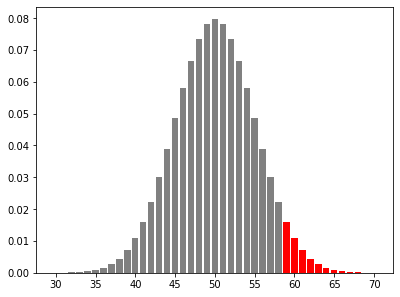

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 100, Rational(1, 2))
d = density(X).dict
werte = list(range(30, 71))
farben = ['red' if k >= 59 else 'gray' for k in werte]
plt.bar(werte, [N(d[k]) for k in werte], color=farben)
plt.show()
```

</details>

## 4. Linksseitiger Test

#### Ablehnungsbereich {0, ..., k} bestimmen

Bei H₀: p ≥ p₀ (Gegenhypothese p < p₀) sprechen **kleine** Werte gegen H₀. Der Ablehnungsbereich ist {0, ..., k} mit dem **größten** k,
für das P(X ≤ k) ≤ α gilt (gerechnet mit p = p₀).

In [ ]:
X = Binomial('X', 100, Rational(1, 2))
F = cdf(X)
alpha = Rational(5, 100)
k = 0
while F[k + 1] <= alpha:
    k += 1
display(k)
display(N(F[k], 4), N(F[k + 1], 4))

#### Aufgabe 4.1

Ein Online-Händler hatte bisher 40 % Stammkunden. Er vermutet einen Rückgang (H₀: p ≥ 0,4). Er befragt 150 Kunden. Bestimme den Ablehnungsbereich {0, ..., k} für α = 5 %
(k und die Irrtumswahrscheinlichkeit mit 4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 49$

$\displaystyle 0.03887$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 150, Rational(4, 10))
F = cdf(X)
alpha = Rational(5, 100)
k = 0
while F[k + 1] <= alpha:
    k += 1
display(k)
N(F[k], 4)
```

</details>

#### Aufgabe 4.2

Eine Firma behauptet, dass 90 % ihrer Kunden zufrieden sind (H₀: p ≥ 0,9). Eine Verbraucherorganisation befragt 100 Kunden. Bestimme den Ablehnungsbereich für α = 1 %.

**Erwartete Ausgabe:**

$\displaystyle 81$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 100, Rational(9, 10))
F = cdf(X)
alpha = Rational(1, 100)
k = 0
while F[k + 1] <= alpha:
    k += 1
k
```

</details>

#### Aufgabe 4.3

Schreibe eine Funktion `links(n, p0, alpha)` für die obere Grenze k des Ablehnungsbereichs beim linksseitigen Test. Teste mit (150, 0,4, 5 %) und (100, 0,9, 1 %).

**Erwartete Ausgabe:**

$\displaystyle 49$

$\displaystyle 81$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def links(n, p0, alpha):
    F = cdf(Binomial('X', n, p0))
    k = 0
    while F[k + 1] <= alpha:
        k += 1
    return k

display(links(150, Rational(4, 10), Rational(5, 100)))
links(100, Rational(9, 10), Rational(1, 100))
```

</details>

#### Aufgabe 4.4

Bei der Befragung des Händlers (n = 150, Ablehnungsbereich {0, ..., 49}) sind in Wirklichkeit nur noch 30 % Stammkunden. Wie groß ist die Wahrscheinlichkeit,
dass der Test den Rückgang **nicht** erkennt (Fehler 2. Art, 4 Ziffern)?

**Erwartete Ausgabe:**

$\displaystyle 0.2101$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Y = Binomial('Y', 150, Rational(3, 10))
N(1 - cdf(Y)[49], 4)
```

</details>

## 5. Zweiseitiger Test (Leistungsfach)

#### Abweichung in beide Richtungen

Bei H₀: p = p₀ und H₁: p ≠ p₀ sprechen **kleine und große** Werte gegen H₀. Man teilt das Signifikanzniveau auf beide Seiten auf:
links {0, ..., kₗ} mit P(X ≤ kₗ) ≤ α/2 und rechts {kᵣ, ..., n} mit P(X ≥ kᵣ) ≤ α/2.

In [ ]:
X = Binomial('X', 100, Rational(1, 2))
F = cdf(X)
halb = Rational(5, 100) / 2
kl = 0
while F[kl + 1] <= halb:
    kl += 1
kr = 1
while 1 - F[kr - 1] > halb:
    kr += 1
display((kl, kr))
N(F[kl] + 1 - F[kr - 1], 4)

#### Aufgabe 5.1

Ein Würfel wird 300-mal geworfen. Teste H₀: p = 1/6 für die Sechs zweiseitig mit α = 5 %. Gib die Grenzen (kₗ, kᵣ) und die gesamte Irrtumswahrscheinlichkeit (4 Ziffern) aus.

**Erwartete Ausgabe:**

$\displaystyle \left( 37, \  64\right)$

$\displaystyle 0.04389$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 300, Rational(1, 6))
alpha = Rational(5, 100)
F = cdf(X)
halb = alpha / 2
kl = 0
while F[kl + 1] <= halb:
    kl += 1
kr = 1
while 1 - F[kr - 1] > halb:
    kr += 1
display((kl, kr))
N(F[kl] + 1 - F[kr - 1], 4)
```

</details>

#### Aufgabe 5.2

In einer Stadt sind 50 % der Einwohner weiblich. In einer Stichprobe von 200 Personen wird geprüft, ob die Stichprobe repräsentativ ist (zweiseitig, α = 10 %).
Gib die Grenzen aus. Wird H₀ bei 87 Frauen verworfen?

**Erwartete Ausgabe:**

$\displaystyle \left( 87, \  113\right)$

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 200, Rational(1, 2))
alpha = Rational(10, 100)
F = cdf(X)
halb = alpha / 2
kl = 0
while F[kl + 1] <= halb:
    kl += 1
kr = 1
while 1 - F[kr - 1] > halb:
    kr += 1
display((kl, kr))
87 <= kl or 87 >= kr
```

</details>

#### Aufgabe 5.3

Schreibe eine Funktion `zweiseitig(n, p0, alpha)`, die das Paar (kₗ, kᵣ) zurückgibt. Teste mit (100, 1/2, 5 %) und (50, 1/5, 5 %).

**Erwartete Ausgabe:**

$\displaystyle \left( 39, \  61\right)$

$\displaystyle \left( 4, \  17\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def zweiseitig(n, p0, alpha):
    F = cdf(Binomial('X', n, p0))
    kl = 0
    while F[kl + 1] <= alpha / 2:
        kl += 1
    kr = 1
    while 1 - F[kr - 1] > alpha / 2:
        kr += 1
    return (kl, kr)

display(zweiseitig(100, Rational(1, 2), Rational(5, 100)))
zweiseitig(50, Rational(1, 5), Rational(5, 100))
```

</details>

## 6. Fehler 2. Art und Stichprobenumfang

#### β hängt vom wahren p ab

Beim rechtsseitigen Test mit Ablehnungsbereich {k, ..., n} ist die Wahrscheinlichkeit für den Fehler 2. Art β(p) = P(X ≤ k − 1), gerechnet mit dem
**wahren** p. Je weiter p von p₀ entfernt ist, desto kleiner ist β. Zeichnet man β(p), erhält man die **Operationscharakteristik** des Tests.

Ein größerer Stichprobenumfang n verkleinert β bei gleichem α.

In [ ]:
n, k = 100, 59
ps = [Rational(i, 100) for i in range(50, 81, 2)]
beta = [N(cdf(Binomial('Y', n, p1))[k - 1], 3) for p1 in ps]
display(beta)
plt.plot([N(p1) for p1 in ps], beta, 'o-')
plt.xlabel('wahres p')
plt.ylabel('β')
plt.show()

#### Aufgabe 6.1

Ein rechtsseitiger Test mit n = 100, p₀ = 0,5 hat den Ablehnungsbereich {59, ..., 100}. Berechne β für p = 0,55, 0,6, 0,7 als Liste (4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle \left[ 0.7585, \  0.3775, \  0.007174\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
[N(cdf(Binomial('Y', 100, p1))[58], 4) for p1 in [Rational(55, 100), Rational(6, 10), Rational(7, 10)]]
```

</details>

#### Aufgabe 6.2

Bestimme für einen rechtsseitigen Test mit p₀ = 0,5, α = 5 % den Ablehnungsbereich bei n = 50, 100 und 200 (Funktion `rechts` von oben) und jeweils β für p = 0,6
(4 Ziffern). Gib eine Liste von Tupeln (n, k, β) aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ \left( 50, \  32, \  0.6644\right), \  \left( 100, \  59, \  0.3775\right), \  \left( 200, \  113, \  0.1397\right)\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def rechts(n, p0, alpha):
    F = cdf(Binomial('X', n, p0))
    k = 1
    while 1 - F[k - 1] > alpha:
        k += 1
    return k

ergebnis = []
for n in [50, 100, 200]:
    k = rechts(n, Rational(1, 2), Rational(5, 100))
    ergebnis.append((n, k, N(cdf(Binomial('Y', n, Rational(6, 10)))[k - 1], 4)))
ergebnis
```

</details>

#### Aufgabe 6.3

Wie groß muss n mindestens sein, damit bei der Regel „verwirf H₀: p ≤ 0,5, wenn X ≥ 0,6·n“ der Fehler 1. Art höchstens 1 % ist? Probiere n = 10, 20, 30, ...
(nur Vielfache von 10) mit einer Schleife.

**Erwartete Ausgabe:**

$\displaystyle 150$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
n = 10
while 1 - cdf(Binomial('X', n, Rational(1, 2)))[6 * n // 10 - 1] > Rational(1, 100):
    n += 10
n
```

</details>

## 7. Gemischte Übungen

#### Aufgabe 7.1

**Tomatensamen:** Der Hersteller gibt eine Keimrate von mindestens 80 % an. Ein Gärtner sät 100 Samen. Er will dem Hersteller nur widersprechen, wenn die Irrtumswahrscheinlichkeit
höchstens 5 % ist. Bei wie vielen gekeimten Samen widerspricht er? Gib k des Ablehnungsbereichs {0, ..., k} aus.

**Erwartete Ausgabe:**

$\displaystyle 72$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
F = cdf(Binomial('X', 100, Rational(8, 10)))
k = 0
while F[k + 1] <= Rational(5, 100):
    k += 1
k
```

</details>

#### Aufgabe 7.2

**Glücksrad:** Ein Glücksrad soll in einem Viertel der Fälle „Gewinn“ zeigen. Ein Spieler glaubt, es zeigt seltener Gewinn. Er beobachtet 80 Drehungen und findet 12 Gewinne.
Berechne P(X ≤ 12) für p = 1/4 (4 Ziffern) und gib aus, ob das auf dem 5-%-Niveau signifikant ist.

**Erwartete Ausgabe:**

$\displaystyle 0.02211$

$\displaystyle \text{True}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
w = cdf(Binomial('X', 80, Rational(1, 4)))[12]
display(N(w, 4))
w <= Rational(5, 100)
```

</details>

#### Aufgabe 7.3

**ESP-Test:** Jemand behauptet, Farben von Karten (rot/schwarz) erraten zu können. In 40 Versuchen soll er so oft richtig liegen, dass ein Zufallstreffer (p = 0,5) mit höchstens 1 %
Wahrscheinlichkeit so gut wäre. Wie viele Treffer braucht er mindestens?

**Erwartete Ausgabe:**

$\displaystyle 28$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
F = cdf(Binomial('X', 40, Rational(1, 2)))
k = 1
while 1 - F[k - 1] > Rational(1, 100):
    k += 1
k
```

</details>

#### Aufgabe 7.4

Wie groß ist beim ESP-Test der vorigen Aufgabe die Wahrscheinlichkeit, dass jemand mit einer echten Trefferquote von 70 % den Test **nicht** besteht (4 Ziffern)?

**Erwartete Ausgabe:**

$\displaystyle 0.4228$

In [ ]:
k = 28
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k = 28
N(cdf(Binomial('Y', 40, Rational(7, 10)))[k - 1], 4)
```

</details>